
Na+(H2O)4 tetrahedral rigid scan
--------------------------------
Selected: R_e = 2.237801 A, spread = 0.002851 A
Default:  R_e = 2.115529 A, spread = 0.002936 A
DFT:      R_e = 2.370604 A, spread = 0.002096 A

Delta R_e selected - default = +0.122272 A
Delta R_e selected - DFT     = -0.132802 A
Delta R_e default - DFT      = -0.255075 A


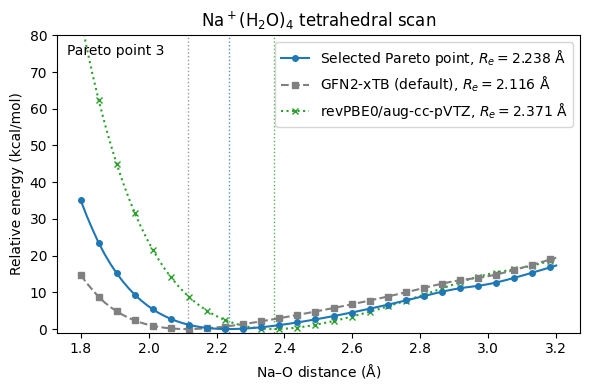


Saved: /dss/dsshome1/09/ge45fol2/cluster_vs_pbc/ML-xTB-project/notebooks_efd_test/analyze_pareto/na_h2o4_tetrahedral_scan.png
Saved: /dss/dsshome1/09/ge45fol2/cluster_vs_pbc/ML-xTB-project/notebooks_efd_test/analyze_pareto/na_h2o4_tetrahedral_scan.pdf


In [2]:
from pathlib import Path
import csv
import re

import matplotlib.pyplot as plt
import numpy as np


# ============================================================
# Settings
# ============================================================

BASELINE_NPZ = Path("/dss/dsshome1/09/ge45fol2/cluster_vs_pbc/ML-xTB-project/notebooks_efd_test/analyze_pareto/pareto_tests/test_pareto_na_215331_20260702_151717/baseline_h2o4_curve.npz")
#SELECTED_NPZ = Path("/dss/dsshome1/09/ge45fol2/cluster_vs_pbc/ML-xTB-project/notebooks_efd_test/analyze_pareto/pareto_tests/test_pareto_na_215335_20260702_160955/point_010_h2o4_curve.npz")
#SELECTED_NPZ = Path('/dss/dsshome1/09/ge45fol2/cluster_vs_pbc/ML-xTB-project/notebooks_efd_test/analyze_pareto/pareto_tests/test_pareto_na_215640_20260715_141704/point_065_h2o4_curve.npz')
SELECTED_NPZ = Path('/dss/dsshome1/09/ge45fol2/cluster_vs_pbc/ML-xTB-project/notebooks_efd_test/analyze_pareto/pareto_tests/test_pareto_na_215334_20260702_155522/point_000_h2o4_curve.npz')
DFT_REFERENCE_DIR = Path(
    "/dss/dsshome1/09/ge45fol2/q-chem-codes/xtb-project/"
    "sm_test/na_h2o4_tet_scan_revpbe0_augccpvtz"
)

SELECTED_LABEL = "Selected Pareto point"
DEFAULT_LABEL = "GFN2-xTB (default)"
DFT_LABEL = "revPBE0/aug-cc-pVTZ"

OUTPUT_NAME = "na_h2o4_tetrahedral_scan"
#POINT_INDEX = 10
#POINT_INDEX = 65
POINT_INDEX = 3

HARTREE_TO_KCAL_MOL = 627.5094740631

QCHEM_ENERGY_PATTERN = re.compile(
    r"Total energy in the final basis set =\s*"
    r"([-+]?(?:\d+\.\d+|\d+)(?:[Ee][-+]?\d+)?)"
)


# ============================================================
# Loaders
# ============================================================

def load_npz_curve(path):
    """
    Load a curve stored as:

        r
        e_ha
    """
    path = Path(path)

    if not path.exists():
        raise FileNotFoundError(f"NPZ file not found: {path}")

    data = np.load(path)

    required_keys = {"r", "e_ha"}
    missing = required_keys.difference(data.files)

    if missing:
        raise KeyError(
            f"{path} is missing keys: {sorted(missing)} "
            f"Available keys: {data.files}"
        )

    r = np.asarray(data["r"], dtype=float)
    e_ha = np.asarray(data["e_ha"], dtype=float)

    if r.ndim != 1 or e_ha.ndim != 1:
        raise ValueError(f"{path}: r and e_ha must be one-dimensional")

    if len(r) != len(e_ha):
        raise ValueError(
            f"{path}: r and e_ha have different lengths: "
            f"{len(r)} and {len(e_ha)}"
        )

    order = np.argsort(r)

    return r[order], e_ha[order]


def load_qchem_scan(ref_dir):
    """
    Load a Q-Chem scan from:

        points.csv
        calculations/<stem>.out

    points.csv must contain:
        stem
        r_angstrom
    """
    ref_dir = Path(ref_dir)
    points_file = ref_dir / "points.csv"
    calculations_dir = ref_dir / "calculations"

    if not points_file.exists():
        raise FileNotFoundError(f"DFT points file not found: {points_file}")

    distances = []
    energies_ha = []

    with points_file.open() as f:
        reader = csv.DictReader(f)

        required_columns = {"stem", "r_angstrom"}
        if reader.fieldnames is None:
            raise ValueError(f"No header found in {points_file}")

        missing = required_columns.difference(reader.fieldnames)
        if missing:
            raise KeyError(
                f"{points_file} is missing columns: {sorted(missing)}"
            )

        for row in reader:
            stem = row["stem"]
            output_file = calculations_dir / f"{stem}.out"

            if not output_file.exists():
                print(f"Warning: missing DFT output, skipping: {output_file}")
                continue

            text = output_file.read_text(errors="replace")
            matches = QCHEM_ENERGY_PATTERN.findall(text)

            if not matches:
                print(
                    f"Warning: final Q-Chem energy not found, skipping: "
                    f"{output_file}"
                )
                continue

            distances.append(float(row["r_angstrom"]))
            energies_ha.append(float(matches[-1]))

    if not distances:
        raise RuntimeError(
            f"No converged DFT scan points were loaded from {ref_dir}"
        )

    distances = np.asarray(distances, dtype=float)
    energies_ha = np.asarray(energies_ha, dtype=float)

    order = np.argsort(distances)

    return distances[order], energies_ha[order]


# ============================================================
# Fit
# ============================================================

def fit_re_quadratic(r, e):
    """
    Estimate R_e from local quadratic fits around the discrete minimum.

    Fits are performed using windows of:
        minimum +/- 2 points
        minimum +/- 3 points
        minimum +/- 4 points

    The +/-3 fit is used as the primary result.

    Returns
    -------
    dict with:
        R_e_A
        R_e_windows
        window_spread_A
        i_min
        quadratic_coefficients
        fit_indices
    """
    r = np.asarray(r, dtype=float)
    e = np.asarray(e, dtype=float)

    if r.ndim != 1 or e.ndim != 1:
        raise ValueError("r and e must be one-dimensional")

    if len(r) != len(e):
        raise ValueError("r and e must have the same length")

    if len(r) < 9:
        raise ValueError(
            "At least 9 scan points are recommended for the local fits"
        )

    i_min = int(np.argmin(e))
    re_windows = {}
    coefficients = {}

    for half_window in (2, 3, 4):
        lo = max(0, i_min - half_window)
        hi = min(len(r) - 1, i_min + half_window)

        r_local = r[lo:hi + 1]
        e_local = e[lo:hi + 1]

        if len(r_local) < 3:
            raise RuntimeError(
                f"Not enough points for +/-{half_window} quadratic fit"
            )

        p = np.polyfit(r_local, e_local, 2)

        if p[0] <= 0:
            raise RuntimeError(
                f"Quadratic fit for +/-{half_window} window is not convex"
            )

        re = -p[1] / (2.0 * p[0])

        re_windows[f"pm{half_window}"] = float(re)
        coefficients[f"pm{half_window}"] = p

    primary_half_window = 3
    lo = max(0, i_min - primary_half_window)
    hi = min(len(r) - 1, i_min + primary_half_window)

    return {
        "R_e_A": re_windows["pm3"],
        "R_e_windows": re_windows,
        "window_spread_A": (
            max(re_windows.values()) - min(re_windows.values())
        ),
        "i_min": i_min,
        "quadratic_coefficients": coefficients["pm3"],
        "fit_indices": (lo, hi),
    }


def shifted_kcal_mol(e_ha):
    """
    Shift a curve to its own minimum and convert Hartree to kcal/mol.
    """
    e_ha = np.asarray(e_ha, dtype=float)
    return (e_ha - np.min(e_ha)) * HARTREE_TO_KCAL_MOL


# ============================================================
# Plotting helper
# ============================================================

def plot_curve(
    ax,
    r,
    e,
    fit,
    label,
    color,
    linestyle,
    marker,
    zorder,
):
    """
    Plot the complete scan and its local quadratic fit.
    """
    ax.plot(
        r,
        e,
        linestyle=linestyle,
        marker=marker,
        color=color,
        linewidth=1.5,
        markersize=4,
        markevery=3,
        label=rf"{label}, $R_e={fit['R_e_A']:.3f}$ Å",
        zorder=zorder
    )

    lo, hi = fit["fit_indices"]
    p = fit["quadratic_coefficients"]

    r_fit = np.linspace(r[lo], r[hi], 300)
    e_fit = np.polyval(p, r_fit)

    ax.plot(
        r_fit,
        e_fit,
        color=color,
        linestyle=linestyle,
        linewidth=2.0,
        zorder=zorder + 0.1
    )

    ax.axvline(
        fit["R_e_A"],
        color=color,
        linestyle=":",
        linewidth=1.0,
        alpha=0.8,
        zorder=1
    )


# ============================================================
# Main
# ============================================================

def main():
    # Load xTB curves
    r_selected, e_selected_ha = load_npz_curve(SELECTED_NPZ)
    r_default, e_default_ha = load_npz_curve(BASELINE_NPZ)

    # Load DFT curve
    r_dft, e_dft_ha = load_qchem_scan(DFT_REFERENCE_DIR)
    np.savez("/dss/dsshome1/09/ge45fol2/cluster_vs_pbc/ML-xTB-project/notebooks_efd_test/analyze_pareto/dft_h2o4_curve.npz", r=r_dft, e_ha=e_dft_ha)


    # Apply exactly the same fit function to all three curves
    fit_selected = fit_re_quadratic(r_selected, e_selected_ha)
    fit_default = fit_re_quadratic(r_default, e_default_ha)
    fit_dft = fit_re_quadratic(r_dft, e_dft_ha)

    # Convert energies for plotting
    e_selected = shifted_kcal_mol(e_selected_ha)
    e_default = shifted_kcal_mol(e_default_ha)
    e_dft = shifted_kcal_mol(e_dft_ha)

    re_selected = fit_selected["R_e_A"]
    re_default = fit_default["R_e_A"]
    re_dft = fit_dft["R_e_A"]

    delta_selected_default = re_selected - re_default
    delta_selected_dft = re_selected - re_dft
    delta_default_dft = re_default - re_dft

    # Print results
    print()
    print("Na+(H2O)4 tetrahedral rigid scan")
    print("--------------------------------")
    print(
        f"Selected: R_e = {re_selected:.6f} A, "
        f"spread = {fit_selected['window_spread_A']:.6f} A"
    )
    print(
        f"Default:  R_e = {re_default:.6f} A, "
        f"spread = {fit_default['window_spread_A']:.6f} A"
    )
    print(
        f"DFT:      R_e = {re_dft:.6f} A, "
        f"spread = {fit_dft['window_spread_A']:.6f} A"
    )
    print()
    print(
        f"Delta R_e selected - default = "
        f"{delta_selected_default:+.6f} A"
    )
    print(
        f"Delta R_e selected - DFT     = "
        f"{delta_selected_dft:+.6f} A"
    )
    print(
        f"Delta R_e default - DFT      = "
        f"{delta_default_dft:+.6f} A"
    )

    # Plot
    fig, ax = plt.subplots(figsize=(6, 4))

    plot_curve(
        ax=ax,
        r=r_selected,
        e=e_selected,
        fit=fit_selected,
        label=SELECTED_LABEL,
        color="C0",
        linestyle="-",
        marker="o",
        zorder=3
    )

    plot_curve(
        ax=ax,
        r=r_default,
        e=e_default,
        fit=fit_default,
        label=DEFAULT_LABEL,
        color="0.5",
        linestyle="--",
        marker="s",
        zorder=2
    )

    plot_curve(
        ax=ax,
        r=r_dft,
        e=e_dft,
        fit=fit_dft,
        label=DFT_LABEL,
        color="C2",
        linestyle=":",
        marker="x",
        zorder=1
    )

    ax.set_xlabel(r"Na–O distance ($\mathrm{\AA}$)")
    ax.set_ylabel(r"Relative energy (kcal/mol)")
    ax.set_title(r"$\mathrm{Na^+(H_2O)_4}$ tetrahedral scan")

    ax.text(
        0.02,
        0.97,
        f"Pareto point {POINT_INDEX}",
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=10
    )

    ax.legend(
        fontsize=10,
        loc="upper right",
        frameon=True
    )

    #ax.set_ylim(bottom=-0.5)
    ax.set_ylim((-1.0, 80))

    fig.tight_layout()

    png_path = Path(f"{OUTPUT_NAME}.png")
    pdf_path = Path(f"{OUTPUT_NAME}.pdf")

    fig.savefig(
        png_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print()
    print(f"Saved: {png_path.resolve()}")
    print(f"Saved: {pdf_path.resolve()}")


if __name__ == "__main__":
    main()